In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix



In [3]:
df = pd.read_csv("Glass.csv")


In [4]:
print(df.head())
print("Shape:", df.shape)
df.info()
print("Missing values:", df.isna().sum())
print("Exact duplicate rows:", df.duplicated().sum())


        RI     Na    Mg    Al     Si     K    Ca   Ba   Fe  \
0  1.52101  13.64  4.49  1.10  71.78  0.06  8.75  0.0  0.0   
1  1.51761  13.89  3.60  1.36  72.73  0.48  7.83  0.0  0.0   
2  1.51618  13.53  3.55  1.54  72.99  0.39  7.78  0.0  0.0   
3  1.51766  13.21  3.69  1.29  72.61  0.57  8.22  0.0  0.0   
4  1.51742  13.27  3.62  1.24  73.08  0.55  8.07  0.0  0.0   

                               Type  
0  building_windows_float_processed  
1  building_windows_float_processed  
2  building_windows_float_processed  
3  building_windows_float_processed  
4  building_windows_float_processed  
Shape: (214, 10)
<class 'pandas.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    

## 1. Target=`Type` ဖြစ်သည်။ နံပါတ်တန်ဖိုး မဟုတ်ဘဲ class label အဖြစ် ခန့်မှန်းနေခြင်းဖြစ်လို့ Classification ဖြစ်သည်။


In [6]:
df = df.drop_duplicates().reset_index(drop=True)
X = df.drop(columns="Type")
y = df["Type"]
print(y.value_counts())
print("Number of classes:", y.nunique())
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=25, stratify=y)


Type
building_windows_non_float_processed    76
building_windows_float_processed        69
headlamps                               29
vehicle_windows_float_processed         17
containers                              13
tableware                                9
Name: count, dtype: int64
Number of classes: 6


## 2. Logistic Baseline
 ဒီ data မှာ label က numeric မဟုတ်လည်း classifier က string label ကိုသုံးနိုင်သည်။ LabelEncoder ကို မဖြစ်မနေထည့်ရန်မလိုပါ။


In [7]:
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, random_state=25))
model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](6,)","['building_windows_float_processed','building_windows_non_float_processed', 'containers','headlamps','tableware','vehicle_windows_float_processed']"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['RI','Na','Mg',...,'Ca','Ba','Fe']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)

pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print(classification_report(y_test, pred, zero_division=0))




Accuracy: 0.640625
                                      precision    recall  f1-score   support

    building_windows_float_processed       0.64      0.67      0.65        21
building_windows_non_float_processed       0.63      0.74      0.68        23
                          containers       0.40      0.50      0.44         4
                           headlamps       0.88      0.78      0.82         9
                           tableware       0.50      0.50      0.50         2
     vehicle_windows_float_processed       0.00      0.00      0.00         5

                            accuracy                           0.64        64
                           macro avg       0.51      0.53      0.52        64
                        weighted avg       0.60      0.64      0.62        64



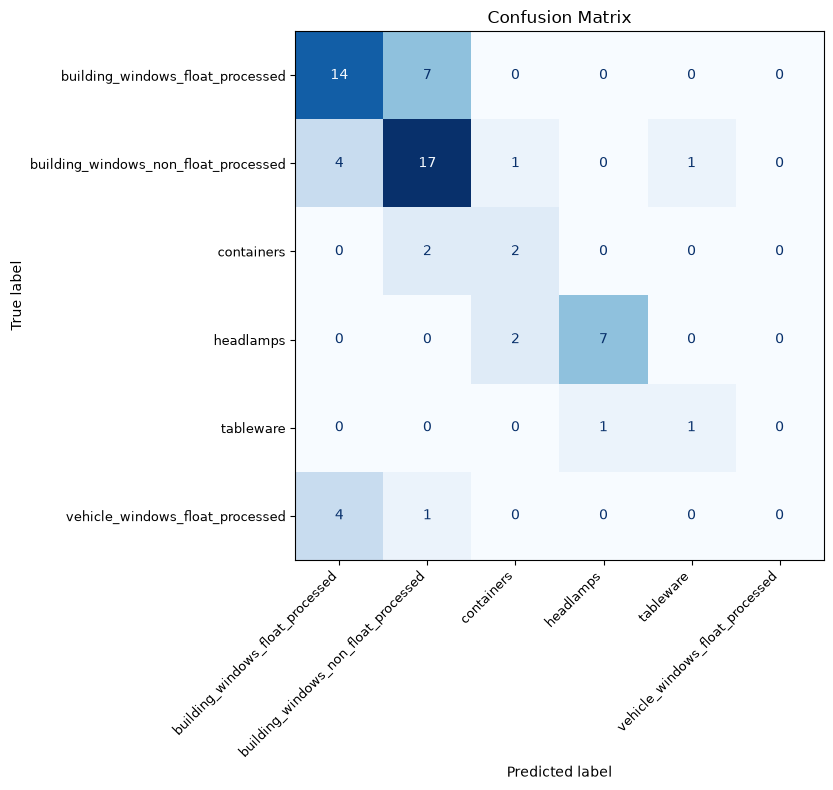

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(12, 8))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    pred,
    labels=model.classes_,
    display_labels=model.classes_,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    xticks_rotation=45,
    ax=ax
)

plt.setp(ax.get_xticklabels(), ha="right", fontsize=9)
plt.setp(ax.get_yticklabels(), fontsize=9)

ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.show()

In [9]:
logistic_result = {"Model":"Logistic Regression", "Accuracy":accuracy_score(y_test, pred),
                   "Macro_F1":f1_score(y_test, pred, average="macro")}
print(logistic_result)


{'Model': 'Logistic Regression', 'Accuracy': 0.640625, 'Macro_F1': 0.5165227744844708}


## 3. Macro F1
Class တစ်ခုချင်းစီ၏ F1 ကို အလေးချိန်တူညီစွာ ပျမ်းမျှယူသည်။ Class အများစု၏ရလဒ်က class အနည်းစုကို ဖုံးကွယ်မနေစေရန် ဖြစ်ပါတယ်။
ဒီ dataset က သေးငယ်လို့ split ပြောင်းရင် ရလဒ်ပြောင်းနိုင်သည်။ Score အမြင့်ဆုံးတစ်ခုတည်း မကြည့်ပါနှင့်။
